# Lab03 – Bài 3: Steepest-ascent & Stochastic Hill Climbing (n-Queens)

**Sinh viên thực hiện:** Nguyễn Hữu Tri — **MSSV:** 3123410387  
**Môn học:** Trí tuệ nhân tạo nâng cao — **Trường Đại học Sài Gòn**  
**Cơ sở thực hiện:** `n_queens.ipynb` và tài liệu hướng dẫn Lab03 của lớp.

**Phạm vi:** Task 1 (Steepest-ascent), Task 2 (Inefficient Stochastic), Task 3 (Efficient Stochastic / First-choice), đo và nhận xét trên `n=4,8`. Chưa triển khai Task 4, Task 5 hoặc Task 6 và chưa làm báo cáo tổng.

**Ghi nhận việc sử dụng công cụ AI:** ChatGPT hỗ trợ viết và kiểm tra notebook, triển khai các hàm, thiết kế thí nghiệm và đánh giá. Người nộp cần đọc hiểu nội dung trước khi sử dụng trong bài nhóm.

## 1. Mục tiêu và quy ước chung

Theo **Bài 3 trong PDF**, cần hoàn thành **Task 1–3 trong `n_queens.ipynb`**, đo *số bước cải thiện*, *số lần đánh giá `conflicts()`*, *giá trị hàm mục tiêu cuối* và *thời gian*. Ba thuật toán là các biến thể hill climbing **không có Random Restart** (phần đó thuộc Bài 4).

Dùng một trạng thái $q=(q_0,\ldots,q_{n-1})$, trong đó mỗi cột có đúng một hậu tại hàng $q_i$. Phép đi lân cận chuyển đúng một hậu sang hàng khác cùng cột; mỗi trạng thái có $M=n(n-1)$ láng giềng. Mục tiêu là cực tiểu hóa $f(q)=\mathrm{conflicts}(q)$ và thành công khi $f=0$.

**Quy tắc tính chỉ số thống nhất:**
- `iterations`: số bước **được chấp nhận** (trạng thái thật sự đổi); không phải số lần thử ngẫu nhiên.
- `candidate_evaluations`: số lần gọi `conflicts()` cho trạng thái láng giềng; `objective_evaluations = candidate_evaluations + 1` tính cả đánh giá trạng thái đầu. Không bao gồm phép kiểm tra `assert`, vẽ bảng và đo ngoài thuật toán.
- `history`: chuỗi $f$ tại trạng thái ban đầu và **sau mỗi bước chấp nhận**, độ dài `iterations + 1`.
- `runtime_ms`: đo `perf_counter()` chỉ quanh lời gọi thuật toán; không tính thời gian tạo bàn cờ, vẽ hình hoặc tổng hợp bảng.
- Mọi thuật toán chỉ chấp nhận **cải thiện nghiêm ngặt** $f(q') < f(q)$; bước bằng điểm không được đi, vì thế có thể kẹt ở plateau.

Khi so sánh theo lần chạy, ba thuật toán nhận đúng **cùng một bàn cờ đầu** và đặt seed riêng cho lựa chọn ngẫu nhiên. Steepest-ascent dùng thứ tự duyệt cố định theo cột, rồi hàng, để khi đồng hạng kết quả tái lập.

## 2. Hàm từ notebook gốc và lớp tiện ích

Cell sau **giữ nguyên** ba hàm `random_board()`, `show_board()` và `conflicts()` từ đề gốc; phần ghép vào `n_queens.ipynb` **không chèn lại cell này**, do notebook chung đã có.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""

    n = len(board)

    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1

    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')

    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

In [2]:
import math
from time import perf_counter
import pandas as pd
from IPython.display import display


def check_board(board):
    """Không chấp nhận bàn cờ sai kích thước/chỉ số hàng; không sửa đầu vào."""
    q = np.asarray(board)
    if q.ndim != 1 or len(q) < 2 or q.dtype.kind not in 'iu':
        raise ValueError('board phải là vector số nguyên, n >= 2.')
    n = len(q)
    if np.any((q < 0) | (q >= n)):
        raise ValueError('Mỗi phần tử phải thuộc [0, n-1].')
    return np.array(q, dtype=int, copy=True)


def local_neighbors(board):
    """Sinh toàn bộ n*(n-1) láng giềng khác nhau, theo thứ tự cột rồi hàng."""
    q = check_board(board)
    n = len(q)
    for col in range(n):
        for row in range(n):
            if row == q[col]:
                continue
            candidate = q.copy()
            candidate[col] = row
            yield candidate


def random_neighbor(board, rng):
    """Lấy đều một láng giềng trong n*(n-1) lựa chọn, không lấy chính nó."""
    q = np.array(board, copy=True)
    n = len(q)
    col = int(rng.integers(n))
    row = int(rng.integers(n - 1))
    if row >= q[col]:
        row += 1
    q[col] = row
    return q


def first_choice_trial_limit(n, miss_probability=0.05):
    """Số lần rút có hoàn lại để P(bỏ lỡ 1 nước đi tốt) <= miss_probability."""
    if n < 2 or not (0 < miss_probability < 1):
        raise ValueError('n >= 2 và miss_probability trong khoảng (0,1).')
    neighbors_count = n * (n - 1)
    return math.ceil(math.log(miss_probability) / math.log1p(-1 / neighbors_count))


def result_dict(method, q, f, history, candidate_evals, reason, attempts=None):
    return {
        'algorithm': method,
        'board': q.copy(), 'conflicts': int(f),
        'history': tuple(int(x) for x in history),
        'iterations': len(history) - 1,
        'candidate_evaluations': int(candidate_evals),
        'objective_evaluations': int(candidate_evals + 1),
        'attempts': int(candidate_evals if attempts is None else attempts),
        'success': bool(f == 0), 'stop_reason': reason,
    }

print('Số láng giềng:', {n: n*(n-1) for n in [4, 8]})
print('Ngưỡng First-choice 95%:', {n: first_choice_trial_limit(n) for n in [4, 8]})

Số láng giềng: {4: 12, 8: 56}
Ngưỡng First-choice 95%: {4: 35, 8: 167}


## 3. Task 1 — Steepest-ascent Hill Climbing

Trong bài toán **min** xung đột, thuật toán này là *steepest-descent* theo $f$, nhưng notebook sử dụng tên **Steepest-ascent** (cực đại hóa $-f$). Với trạng thái hiện tại: xét **tất cả** láng giềng, chọn láng giềng có $f$ nhỏ nhất. Chỉ chuyển nếu có cải thiện; nếu không, kết luận **không có láng giềng tốt hơn** trong toán tử đã định nghĩa, tức một cực tiểu cục bộ (có thể là plateau).

Chi phí mỗi bước duyệt đầy đủ là $M=n(n-1)$ lượt `conflicts()`. Mặc định nếu bằng nhau thì giữ lựa chọn xuất hiện trước; quy tắc không ngẫu nhiên này có thể ảnh hưởng nghiệm cuối.

In [3]:
def hill_climb_steepest(board, seed=None, max_steps=100, max_evaluations=5000):
    """Task 1: xét hết láng giềng và lấy một bước tốt nhất; không random restart."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    n = len(q)
    m = n * (n - 1)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations + m > max_evaluations:
            reason = 'evaluation_budget'
            break
        best = None
        best_f = f
        for candidate in local_neighbors(q):
            fc = int(conflicts(candidate))
            evaluations += 1
            if fc < best_f:
                best, best_f = candidate, fc
        if best is None:
            reason = 'local_optimum'
            break
        q, f = best, best_f
        history.append(f)

    if f == 0:
        reason = 'solved'
    return result_dict('Steepest-ascent', q, f, history, evaluations, reason)

example_q = np.array([0, 0, 0, 0])
r = hill_climb_steepest(example_q)
print('Ví dụ Task 1:', {k:v for k,v in r.items() if k not in ('board','history')})
print('Đường f:', r['history'], '| q cuối:', r['board'].tolist())
assert r['objective_evaluations'] == r['candidate_evaluations'] + 1

Ví dụ Task 1: {'algorithm': 'Steepest-ascent', 'conflicts': 0, 'iterations': 3, 'candidate_evaluations': 36, 'objective_evaluations': 37, 'attempts': 36, 'success': True, 'stop_reason': 'solved'}
Đường f: (6, 3, 1, 0) | q cuối: [1, 3, 0, 2]


## 4. Task 2 — Inefficient Stochastic Hill Climbing

Liệt kê **toàn bộ** láng giềng và đánh giá $f$ từng trạng thái; lọc những trạng thái có $f(q')<f(q)$, sau đó chọn **đều ngẫu nhiên** một trạng thái tốt hơn. Nếu không có bước tốt, dừng và kết luận cực tiểu cục bộ. Khác Task 1, mỗi bước không nhất thiết giảm $f$ mạnh nhất; khác Task 3, **phải đánh giá tất cả** láng giềng mỗi lần.

In [4]:
def hill_climb_stochastic_all(board, seed=0, max_steps=100, max_evaluations=5000):
    """Task 2: liệt kê mọi nước đi tốt rồi chọn ngẫu nhiên một nước đi."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    rng = np.random.default_rng(seed)
    n = len(q)
    m = n * (n - 1)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations + m > max_evaluations:
            reason = 'evaluation_budget'
            break
        improvements = []
        for candidate in local_neighbors(q):
            fc = int(conflicts(candidate))
            evaluations += 1
            if fc < f:
                improvements.append((candidate, fc))
        if not improvements:
            reason = 'local_optimum'
            break
        index = int(rng.integers(len(improvements)))
        q, f = improvements[index]
        history.append(f)

    if f == 0:
        reason = 'solved'
    return result_dict('Stochastic-all', q, f, history, evaluations, reason)

r = hill_climb_stochastic_all(example_q, seed=2026)
print('Ví dụ Task 2:', {k:v for k,v in r.items() if k not in ('board','history')})
print('Đường f:', r['history'], '| q cuối:', r['board'].tolist())

Ví dụ Task 2: {'algorithm': 'Stochastic-all', 'conflicts': 1, 'iterations': 3, 'candidate_evaluations': 48, 'objective_evaluations': 49, 'attempts': 48, 'success': False, 'stop_reason': 'local_optimum'}
Đường f: (6, 4, 2, 1) | q cuối: [3, 1, 0, 2]


## 5. Task 3 — Efficient Stochastic / First-choice Hill Climbing

Mỗi lần chỉ **lấy ngẫu nhiên một láng giềng** trong $M=n(n-1)$ lựa chọn và gọi `conflicts()` **một lần**. Nếu giảm $f$, nhận bước đó và đặt lại bộ đếm số thử thất bại; nếu không, thử tiếp. Khi chưa cải thiện trong $L$ lượt rút liên tiếp thì dừng.

**Chọn ngưỡng dừng có căn cứ:** Mỗi lượt rút có hoàn lại từ $M$ láng giềng và giả sử còn **ít nhất một nước đi tốt**, xác suất bỏ lỡ một nước đi tốt cố định qua $L$ lượt là $(1-1/M)^L$. Để xác suất này không vượt 5%, chọn:

$$L=\left\lceil \frac{\ln(0.05)}{\ln(1-1/M)} \right\rceil.$$ 

Với $n=4$: $M=12$, $L=35$; $n=8$: $M=56$, $L=167$. Đây là **đảm bảo xác suất có điều kiện** dựa trên việc lấy mẫu đều, độc lập **tại một trạng thái cố định**, không phải đảm bảo đã duyệt toàn bộ láng giềng. Kết quả `trial_limit` không được gọi là “chứng minh cực trị cục bộ”. Với nhiều trạng thái đã đi qua, xác suất bỏ sót ít nhất một lần có thể lớn hơn 5%.

In [5]:
def hill_climb_first_choice(board, seed=0, max_steps=100,
                            max_evaluations=5000, max_no_improvement_trials=None):
    """Task 3: rút ngẫu nhiên từng láng giềng; ngừng nếu lâu không cải thiện."""
    q = check_board(board)
    if max_steps < 1 or max_evaluations < 1:
        raise ValueError('max_steps và max_evaluations phải dương.')
    n = len(q)
    if max_no_improvement_trials is None:
        max_no_improvement_trials = first_choice_trial_limit(n)
    if max_no_improvement_trials < 1:
        raise ValueError('max_no_improvement_trials phải dương.')
    rng = np.random.default_rng(seed)
    f = int(conflicts(q))
    history = [f]
    evaluations = 0
    unsuccessful_streak = 0
    reason = 'step_budget'

    while len(history) - 1 < max_steps:
        if f == 0:
            reason = 'solved'
            break
        if evaluations >= max_evaluations:
            reason = 'evaluation_budget'
            break
        if unsuccessful_streak >= max_no_improvement_trials:
            reason = 'trial_limit'  # không khẳng định chắc chắn local optimum
            break
        candidate = random_neighbor(q, rng)
        fc = int(conflicts(candidate))
        evaluations += 1
        if fc < f:
            q, f = candidate, fc
            history.append(f)
            unsuccessful_streak = 0
        else:
            unsuccessful_streak += 1

    if f == 0:
        reason = 'solved'
    return result_dict('First-choice', q, f, history, evaluations, reason)

r = hill_climb_first_choice(example_q, seed=2026)
print('Ví dụ Task 3:', {k:v for k,v in r.items() if k not in ('board','history')})
print('Đường f:', r['history'], '| q cuối:', r['board'].tolist())

Ví dụ Task 3: {'algorithm': 'First-choice', 'conflicts': 0, 'iterations': 4, 'candidate_evaluations': 7, 'objective_evaluations': 8, 'attempts': 7, 'success': True, 'stop_reason': 'solved'}
Đường f: (6, 4, 3, 2, 0) | q cuối: [2, 0, 3, 1]


## 6. Kiểm thử độc lập trước khi đo đạc

Không chỉ dựa vào việc code chạy không lỗi: sử dụng hàm đếm xung đột theo cặp hậu khác với mã nhóm của giảng viên, **vét cạn mọi trạng thái $4^4=256$**, kiểm tra láng giềng hợp lệ/duy nhất, không làm biến đổi đầu vào, giảm $f$ nghiêm ngặt, tính đúng của kết quả trả về và điều kiện dừng. Với Steepest và Stochastic-all, nếu dừng vì `local_optimum`, kiểm tra bằng vét cạn không tồn tại láng giềng cải thiện. Với First-choice, ghi nhận bao nhiêu trường hợp dừng theo ngưỡng nhưng **vẫn còn** nước đi cải thiện.

In [6]:
from itertools import product


def independent_conflicts(board):
    n = len(board)
    return sum(bool(board[i] == board[j] or abs(int(board[i])-int(board[j])) == j-i)
               for i in range(n) for j in range(i+1, n))


def has_improving_neighbor(board):
    f = int(conflicts(board))
    return any(int(conflicts(q2)) < f for q2 in local_neighbors(board))

rng8 = np.random.default_rng(712)
for n, cases in [(4, product(range(4), repeat=4)),
                 (8, (rng8.integers(0, 8, 8) for _ in range(1000)))]:
    verified = 0
    for board_values in cases:
        b = np.asarray(board_values, dtype=int)
        assert int(conflicts(b)) == independent_conflicts(b)
        neighbors = list(local_neighbors(b))
        assert len(neighbors) == n*(n-1)
        assert len({tuple(x) for x in neighbors}) == n*(n-1)
        assert all(np.count_nonzero(c != b) == 1 for c in neighbors)
        verified += 1
    print(f'PASS: n={n}, {verified} trạng thái, đếm xung đột + toán tử láng giềng đúng')

algorithms = [hill_climb_steepest, hill_climb_stochastic_all, hill_climb_first_choice]
for n in (4, 8):
    for trial in range(100):
        start = np.random.default_rng(12345 + n*1000 + trial).integers(0, n, n)
        saved = start.copy()
        for function in algorithms:
            z = function(start, seed=trial)
            assert np.array_equal(start, saved), 'Hàm không được sửa board đầu vào'
            assert int(conflicts(z['board'])) == z['conflicts']
            assert z['objective_evaluations'] == z['candidate_evaluations'] + 1
            assert len(z['history']) == z['iterations'] + 1
            assert z['history'][0] == int(conflicts(start))
            assert z['history'][-1] == z['conflicts']
            assert all(b < a for a,b in zip(z['history'], z['history'][1:]))
            assert z['success'] == (z['conflicts'] == 0)
            assert z['iterations'] <= int(conflicts(start))
            if z['stop_reason'] == 'local_optimum':
                assert not has_improving_neighbor(z['board'])
            if z['stop_reason'] == 'trial_limit':
                assert function == hill_climb_first_choice
            if function == hill_climb_steepest:
                m = n*(n-1)
                assert z['candidate_evaluations'] % m == 0
print('PASS: 600 lượt chạy kiểm tra tính đúng/điều kiện dừng')
assert np.array_equal(hill_climb_first_choice([1,3,0,2])['board'], [1,3,0,2])
for function in algorithms:
    a = function(np.array([0,1,2,3]),seed=99)
    b = function(np.array([0,1,2,3]),seed=99)
    assert np.array_equal(a['board'],b['board']) and a['history'] == b['history']
print('PASS: nghiệm 4 hậu, tái lập với cùng seed, không sửa đầu vào')

PASS: n=4, 256 trạng thái, đếm xung đột + toán tử láng giềng đúng
PASS: n=8, 1000 trạng thái, đếm xung đột + toán tử láng giềng đúng


PASS: 600 lượt chạy kiểm tra tính đúng/điều kiện dừng
PASS: nghiệm 4 hậu, tái lập với cùng seed, không sửa đầu vào


## 7. Thực nghiệm chính: cùng đầu vào, nhiều lần chạy

Với mỗi $n\in\{4,8\}$, dùng **100 bàn cờ ngẫu nhiên được cố định trước**, seed sinh bàn cờ `20261016 + 1000*n`; ba thuật toán nhận cùng vector bắt đầu ở từng lượt. Các thuật toán ngẫu nhiên dùng `seed = 90000 + 1000*n + trial`. Không sử dụng Random Restart.

**Ngân sách mỗi lần chạy:** tối đa `100` bước chấp nhận hoặc `5.000` đánh giá láng giềng; First-choice dùng ngưỡng theo công thức mức bỏ sót 5% ở mỗi trạng thái. Với mọi thuật toán, `success_rate` = số lần đạt $f=0$ chia tổng số lần. Thời gian tính bằng millisecond mỗi lần chạy, lấy **trung bình** và báo thêm **trung vị**; kết quả có thể thay đổi theo máy dù seed cố định. Không dùng lần kiểm thử ở mục 6 làm số liệu đánh giá.

In [7]:
LABELS = {
    'Steepest-ascent': hill_climb_steepest,
    'Stochastic-all': hill_climb_stochastic_all,
    'First-choice': hill_climb_first_choice,
}
BENCH_RUNS = 100
BENCH_N = (4, 8)
BENCH_BUDGET = dict(max_steps=100, max_evaluations=5000)
records = []
bench_history = {}
for n in BENCH_N:
    starts_rng = np.random.default_rng(20261016 + 1000*n)
    initial_boards = starts_rng.integers(0, n, size=(BENCH_RUNS, n))
    methods = list(LABELS.items())
    for trial, start in enumerate(initial_boards):
        seed = 90000 + 1000*n + trial
        # Xoay thứ tự để tránh thiên lệch nếu điều kiện CPU thay đổi chậm theo thời gian.
        rotation = trial % len(methods)
        for label, fn in methods[rotation:] + methods[:rotation]:
            start_saved = start.copy()
            tic = perf_counter()
            res = fn(start, seed=seed, **BENCH_BUDGET)
            runtime_ms = (perf_counter() - tic) * 1000
            assert np.array_equal(start, start_saved)
            assert res['conflicts'] == int(conflicts(res['board']))
            bench_history[n, trial, label] = res['history']
            records.append({
                'n': n, 'trial': trial, 'algorithm': label,
                'initial_f': int(conflicts(start)), 'final_f': res['conflicts'],
                'success': int(res['success']), 'iterations': res['iterations'],
                'candidate_evaluations': res['candidate_evaluations'],
                'objective_evaluations': res['objective_evaluations'],
                'runtime_ms': runtime_ms, 'stop_reason': res['stop_reason'],
                'false_stall': bool(res['stop_reason']=='trial_limit'
                                    and has_improving_neighbor(res['board'])),
            })
benchmark_df = pd.DataFrame(records)
benchmark_summary = (benchmark_df.groupby(['n','algorithm'], sort=False)
    .agg(runs=('trial','size'), initial_f=('initial_f','mean'),
         mean_final_f=('final_f','mean'), success_rate=('success','mean'),
         mean_iterations=('iterations','mean'),
         mean_objective_evals=('objective_evaluations','mean'),
         mean_runtime_ms=('runtime_ms','mean'), median_runtime_ms=('runtime_ms','median'),
         false_stalls=('false_stall','sum')))
print('BẢNG TỔNG HỢP - 100 lần chạy cho từng n và từng thuật toán')
display(benchmark_summary.round(3))
print('Số lần dừng theo nguyên nhân:')
display(pd.crosstab([benchmark_df.n, benchmark_df.algorithm], benchmark_df.stop_reason))
assert len(benchmark_df) == 2*3*BENCH_RUNS
assert benchmark_df.candidate_evaluations.ge(0).all()

BẢNG TỔNG HỢP - 100 lần chạy cho từng n và từng thuật toán


runs  initial_f  ...  median_runtime_ms  false_stalls
n algorithm                         ...                                 
4 Steepest-ascent   100       3.27  ...              0.103             0
  Stochastic-all    100       3.27  ...              0.164             0
  First-choice      100       3.27  ...              0.268             1
8 Steepest-ascent   100       8.37  ...              1.334             0
  Stochastic-all    100       8.37  ...              2.087             0
  First-choice      100       8.37  ...              1.863             1

[6 rows x 9 columns]

Số lần dừng theo nguyên nhân:


stop_reason        local_optimum  solved  trial_limit
n algorithm                                          
4 First-choice                 0      28           72
  Steepest-ascent             61      39            0
  Stochastic-all              76      24            0
8 First-choice                 0      11           89
  Steepest-ascent             87      13            0
  Stochastic-all              85      15            0

### Diễn giải kết quả có số liệu cụ thể

Cell tiếp theo tự đọc bảng thí nghiệm thực tế để sinh nhận xét, thay vì ghi sẵn con số từ một lần chạy.

In [8]:
from IPython.display import Markdown
paragraphs=[]
for n in BENCH_N:
    part=benchmark_summary.loc[n]
    for algorithm in LABELS:
        row=part.loc[algorithm]
        paragraphs.append(
            f'- **n={n} — {algorithm}:** giải được **{int(round(row.success_rate*BENCH_RUNS))}/{BENCH_RUNS}** lượt '
            f'({row.success_rate:.0%}); $f$ cuối trung bình **{row.mean_final_f:.2f}**, '
            f'**{row.mean_iterations:.2f}** bước cải thiện, **{row.mean_objective_evals:.2f}** lượt đánh giá '
            f'và **{row.mean_runtime_ms:.3f} ms** mỗi lần chạy; '
            f'dừng sớm sai do ngưỡng thử: **{int(row.false_stalls)}** lượt.'
        )
    best_success=part.success_rate.max()
    winners=part[part.success_rate==best_success].index.tolist()
    paragraphs.append(f'\nTrên **n={n}**, tỷ lệ thành công cao nhất thuộc về **{", ".join(winners)}** '
                      f'({best_success:.0%}) ở bộ 100 seed này. Đây không phải một kết luận bảo đảm cho mọi n hay mọi seed.\n')
display(Markdown('\n'.join(paragraphs)))

- **n=4 — Steepest-ascent:** giải được **39/100** lượt (39%); $f$ cuối trung bình **0.70**, **1.57** bước cải thiện, **27.16** lượt đánh giá và **0.116 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=4 — Stochastic-all:** giải được **24/100** lượt (24%); $f$ cuối trung bình **0.90**, **1.88** bước cải thiện, **32.68** lượt đánh giá và **0.172 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=4 — First-choice:** giải được **28/100** lượt (28%); $f$ cuối trung bình **0.83**, **1.88** bước cải thiện, **35.48** lượt đánh giá và **0.253 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **1** lượt.

Trên **n=4**, tỷ lệ thành công cao nhất thuộc về **Steepest-ascent** (39%) ở bộ 100 seed này. Đây không phải một kết luận bảo đảm cho mọi n hay mọi seed.

- **n=8 — Steepest-ascent:** giải được **13/100** lượt (13%); $f$ cuối trung bình **1.30**, **3.14** bước cải thiện, **225.56** lượt đánh giá và **1.425 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=8 — Stochastic-all:** giải được **15/100** lượt (15%); $f$ cuối trung bình **1.27**, **5.13** bước cải thiện, **335.88** lượt đánh giá và **2.146 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **0** lượt.
- **n=8 — First-choice:** giải được **11/100** lượt (11%); $f$ cuối trung bình **1.40**, **5.04** bước cải thiện, **206.66** lượt đánh giá và **1.898 ms** mỗi lần chạy; dừng sớm sai do ngưỡng thử: **1** lượt.

Trên **n=8**, tỷ lệ thành công cao nhất thuộc về **Stochastic-all** (15%) ở bộ 100 seed này. Đây không phải một kết luận bảo đảm cho mọi n hay mọi seed.


### Biểu đồ so sánh tỉ lệ thành công, chi phí và chất lượng

Biểu đồ dưới cho thấy **tỷ lệ đạt $f=0$**, số lần gọi hàm mục tiêu và giá trị $f$ cuối trung bình. Phải xem ba chỉ số cùng nhau: thuật toán đánh giá ít hơn chưa chắc tìm nghiệm tốt hơn; số bước chấp nhận ít cũng không đồng nghĩa chi phí đánh giá thấp.

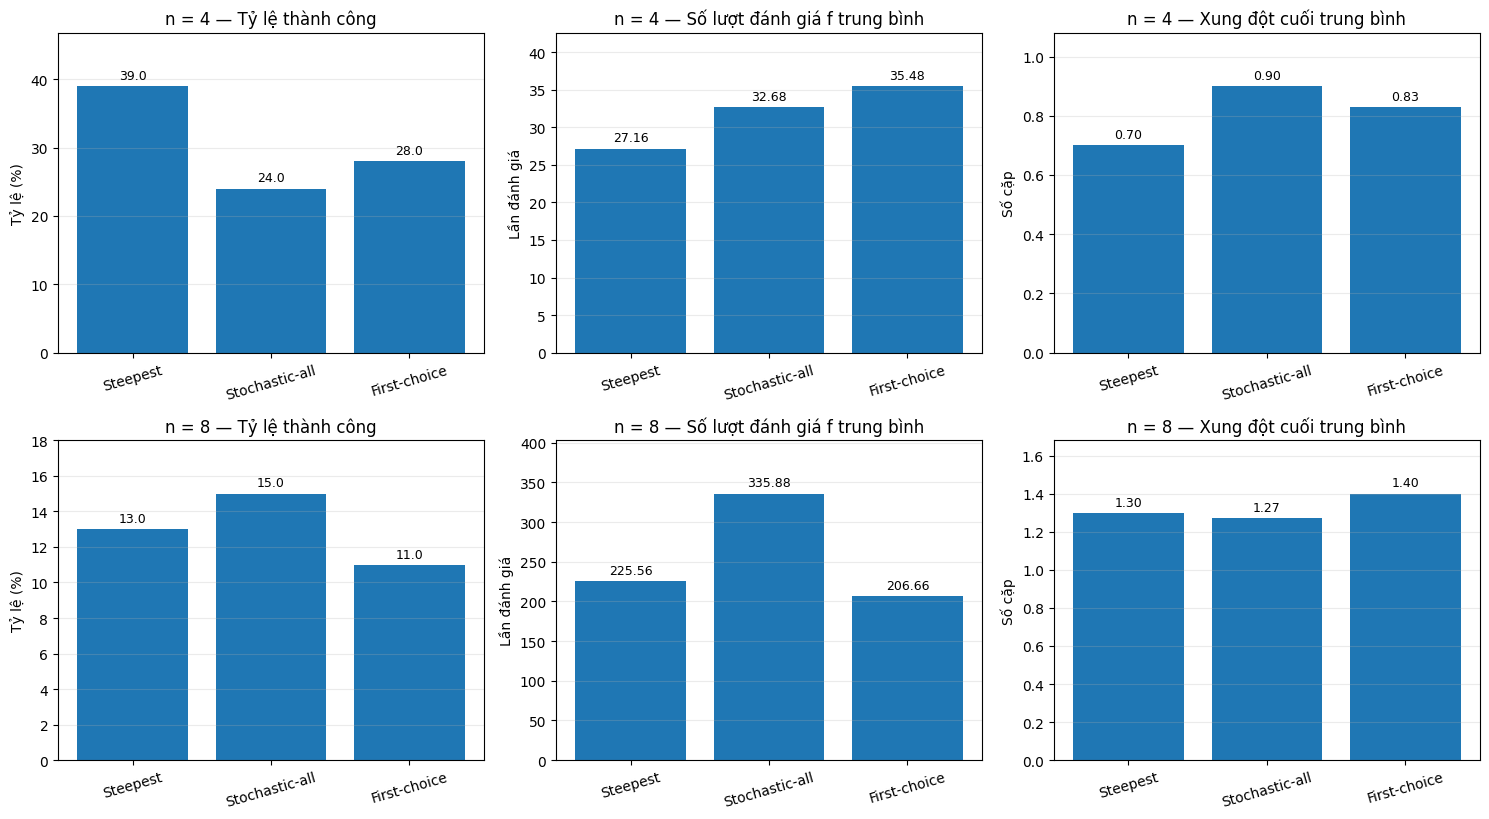

In [9]:
fig, axarr = plt.subplots(2, 3, figsize=(15, 8.3))
for row,n in enumerate(BENCH_N):
    part = benchmark_summary.loc[n].reindex(LABELS)
    labels = ['Steepest', 'Stochastic-all', 'First-choice']
    charts = [
        ('success_rate','Tỷ lệ thành công',100,'Tỷ lệ (%)'),
        ('mean_objective_evals','Số lượt đánh giá f trung bình',1,'Lần đánh giá'),
        ('mean_final_f','Xung đột cuối trung bình',1,'Số cặp'),
    ]
    for col,(key,title,mult,yname) in enumerate(charts):
        ax=axarr[row,col]
        values=(part[key]*mult).to_numpy()
        bars=ax.bar(labels,values)
        ax.set_title(f'n = {n} — {title}')
        ax.set_ylabel(yname)
        ax.tick_params(axis='x',labelrotation=16)
        ax.grid(axis='y',alpha=.25)
        ax.bar_label(bars,fmt='%.1f' if col==0 else '%.2f',padding=3,fontsize=9)
        ax.set_ylim(0,max(1,float(values.max())*1.2))
plt.tight_layout()
plt.show()

### Đường hội tụ đại diện

Chọn **cùng một bàn cờ ban đầu** ở `trial=0` để minh họa, đường $f$ ghi sau mỗi **bước được chấp nhận**. Các đường có độ dài khác nhau do thuật toán dừng sớm. Đây chỉ là hình minh họa một lượt, **không phải** đường hội tụ trung bình; Task 6 trong Bài 8 sẽ khảo sát hội tụ toàn diện hơn.

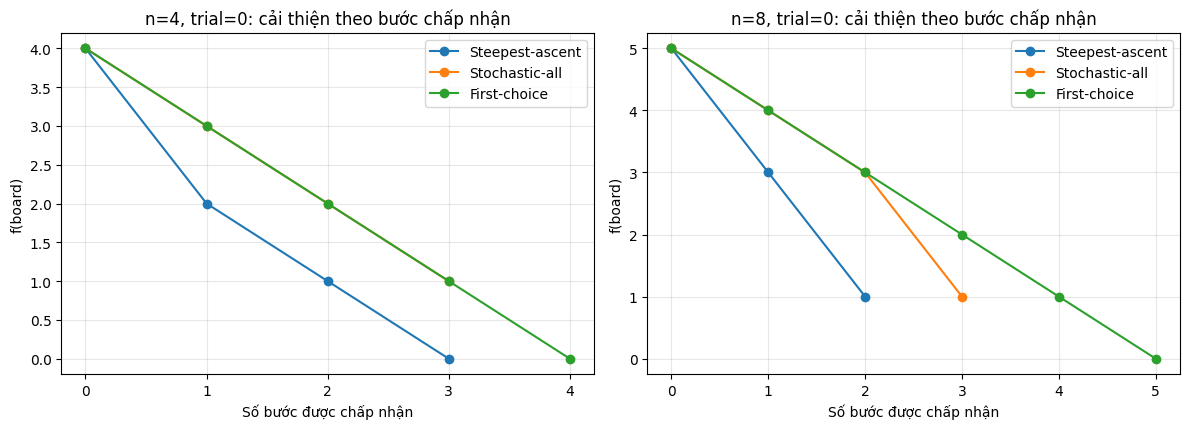

In [10]:
fig, axes=plt.subplots(1,2,figsize=(12,4.4))
for axis,n in zip(axes,BENCH_N):
    for label in LABELS:
        hist=bench_history[n,0,label]
        axis.plot(range(len(hist)),hist,marker='o',label=label)
    axis.set_title(f'n={n}, trial=0: cải thiện theo bước chấp nhận')
    axis.set_xlabel('Số bước được chấp nhận')
    axis.set_ylabel('f(board)')
    axis.set_xticks(range(0,max(len(bench_history[n,0,k]) for k in LABELS)))
    axis.grid(alpha=.3)
    axis.legend()
plt.tight_layout()
plt.show()

## 8. Khảo sát riêng điều kiện dừng First-choice

Với $M=56$ láng giềng ở $n=8$, xét ba ngưỡng $L=M/2=28$, $L=M=56$ và ngưỡng xác suất 95% ($L=167$), sử dụng **100 bàn cờ đầu giống nhau** cho cả ba ngưỡng. Thống kê:
- số lượt đánh giá $f$ trung bình;
- tỷ lệ đạt nghiệm;
- `false_stall_rate`: phần trăm lượt thuật toán dừng do thử quá nhiều lần **nhưng thực tế vẫn còn** láng giềng tốt hơn, kiểm tra độc lập sau khi thuật toán đã kết thúc (**không tính** phần kiểm tra vào thời gian/số đánh giá của thuật toán).

Không áp dụng kiểm định này để tuyên bố bảo đảm 95% cho **toàn bộ lượt chạy**, vì mỗi lần thuật toán có thể đã qua nhiều trạng thái.

In [11]:
n=8
m=n*(n-1)
limits=[m//2, m, first_choice_trial_limit(n)]
assert limits==[28,56,167]
rng=np.random.default_rng(20261016 + 8000)
starts=rng.integers(0,n,size=(100,n))
sens_records=[]
for trial,initial in enumerate(starts):
    for limit in limits:
        tic=perf_counter()
        res=hill_climb_first_choice(initial,seed=90000+8000+trial,
                                    max_no_improvement_trials=limit,**BENCH_BUDGET)
        elapsed=(perf_counter()-tic)*1000
        false_stall=bool(res['stop_reason']=='trial_limit' and has_improving_neighbor(res['board']))
        sens_records.append({'trial':trial,'limit':limit,'success':int(res['success']),
                             'objective_evaluations':res['objective_evaluations'],
                             'runtime_ms':elapsed,'false_stall':int(false_stall)})
sensitivity=pd.DataFrame(sens_records)
sensitivity_summary=(sensitivity.groupby('limit')
    .agg(success_rate=('success','mean'),mean_evaluations=('objective_evaluations','mean'),
         mean_ms=('runtime_ms','mean'),false_stall_rate=('false_stall','mean')))
print('Ngưỡng thử không cải thiện liên tiếp (n=8, cùng 100 bàn cờ):')
display(sensitivity_summary.round(3))

Ngưỡng thử không cải thiện liên tiếp (n=8, cùng 100 bàn cờ):


,success_rate,mean_evaluations,mean_ms,false_stall_rate
limit,,,,
28,0.04,53.21,0.579,0.43
56,0.09,91.54,0.966,0.19
167,0.11,206.66,2.084,0.01


## 9. Nhận xét và kết luận

**So sánh về cơ chế:** Steepest chọn bước tốt nhất toàn bộ láng giềng, còn Stochastic-all chọn ngẫu nhiên một nước tốt. Vì cùng quét hết $M$ láng giềng mỗi vòng, hai biến thể có chi phí đánh giá khoảng $M$ mỗi vòng (trừ việc dừng sớm khi đã đến nghiệm). First-choice chỉ gọi `conflicts()` một lần mỗi lần thử và có thể đi nhanh hơn khi dễ gặp bước tốt; nhưng để tránh ngừng quá sớm ở vùng ít bước tốt, phải cho phép thử nhiều lần. **Không thuật toán nào trong ba thuật toán luôn thoát khỏi cực trị cục bộ**, vì đều chỉ nhận bước giảm $f$.

**Diễn giải từ kết quả thực tế:** Bảng phía trên là căn cứ để nhận xét thuật toán nào đạt tỷ lệ $f=0$ cao hơn và đánh đổi bao nhiêu lượt đánh giá. Chi phí thời gian thực phụ thuộc cách cài đặt, kích thước bài toán và máy đo; không suy ra tốc độ chỉ từ tên thuật toán. Do chạy ngẫu nhiên, 100 lần cho mỗi cấu hình chỉ là ước lượng trên những seed đã chọn, không bảo đảm thứ hạng trên mọi trường hợp.

**Giới hạn:** Không dùng Random Restart, Simulated Annealing, lịch giảm nhiệt hoặc khả năng mở rộng lên $n=12,16,20$ trong Bài 3. Các nội dung đó thuộc Bài 4, 5 và 8. Điều kiện dừng `trial_limit` không phải bằng chứng cực trị cục bộ thực sự.

## 10. Lưu số liệu thô

Hai file CSV bên dưới được tạo từ các bản ghi từng lượt chạy. Dữ liệu này giúp nhóm kiểm tra lại số trung bình, số lượt thành công và truy vết từng seed khi làm Task 6 ở Bài 8. Thời gian thực thi trong file chỉ có ý nghĩa ở môi trường đã đo.

In [12]:
from pathlib import Path
result_dir = Path('ket_qua_bai3')
result_dir.mkdir(parents=True, exist_ok=True)
benchmark_df.to_csv(result_dir / 'bai3_thuc_nghiem_100_luot.csv', index=False)
sensitivity.to_csv(result_dir / 'bai3_first_choice_nguong_dung.csv', index=False)
print('Đã lưu dữ liệu thô:', (result_dir / 'bai3_thuc_nghiem_100_luot.csv'),
      'và', (result_dir / 'bai3_first_choice_nguong_dung.csv'))
assert len(benchmark_df) == 600 and len(sensitivity)==300

Đã lưu dữ liệu thô: ket_qua_bai3/bai3_thuc_nghiem_100_luot.csv và ket_qua_bai3/bai3_first_choice_nguong_dung.csv
